In [89]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
from torchvision import datasets, transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image, preprocess_image
from utils.image_utils import add_black_patch, add_noise, blur_image


# Configuration
IMG_PATH = 'failure_images/Agriculture_pred_Grassland_720.jpg'  # Target image path
MODEL_PATH = 'best_model.pth'
MODEL_NAME = 'seresnet50'
NUM_CLASSES = 15
DATASET_PATH = 'dataset/aerial_landscapes'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TARGET_LAYER = 'layer4[-1]'


In [90]:
# Image to tensor preprocessing
to_tensor = transforms.Compose([
    transforms.ToTensor(),
])

# Extract class names
dataset = datasets.ImageFolder(DATASET_PATH)
class_names = dataset.classes

# Prediction function
def get_prediction(model, image_np):
    image_tensor = to_tensor(image_np).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        outputs = model(image_tensor)
        _, predicted = torch.max(outputs, 1)
    idx = predicted.item()
    return idx, class_names[idx]


In [91]:
# GradCAM function
def run_gradcam(model, rgb_np):
    input_tensor = preprocess_image(rgb_np, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    target_layers = [eval(f"model.{TARGET_LAYER}")]

    cam = GradCAM(model=model, target_layers=target_layers)
    targets = None
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
    cam_img = show_cam_on_image(rgb_np, grayscale_cam, use_rgb=True)
    return cam_img

In [92]:
# Show image
def show_single_comparison(image, cam_image, title, class_name):

    print(f"The image is predicted as: {class_name}")
    fig, axes = plt.subplots(1, 2, figsize=(5, 6))

    axes[0].imshow(image)
    axes[0].set_title(f"{title} Image")
    axes[0].axis("off")

    axes[1].imshow(cam_image)
    axes[1].set_title(f"{title} Grad-CAM")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


In [93]:
# Load model
model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval().to(DEVICE)

# Read and preprocess original image
origin_img = Image.open(IMG_PATH).convert("RGB")
rgb_np = np.array(origin_img).astype(np.float32) / 255.0

# Generate perturbed images
blurred = blur_image(rgb_np)
occluded = add_black_patch(rgb_np)
noisy = add_noise(rgb_np)

# Grad-CAM visualization
cam_original = run_gradcam(model, rgb_np)
cam_blur = run_gradcam(model, blurred)
cam_occl = run_gradcam(model, occluded)
cam_noise = run_gradcam(model, noisy)


The image is predicted as: (6, 'Grassland')


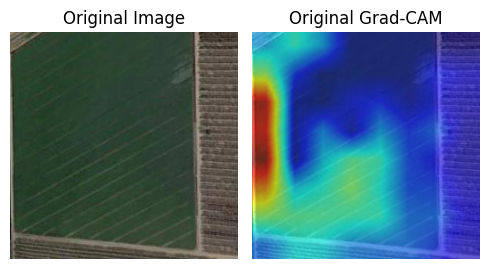

In [94]:
show_single_comparison(rgb_np, cam_original, "Original", get_prediction(model, rgb_np))

The image is predicted as: (6, 'Grassland')


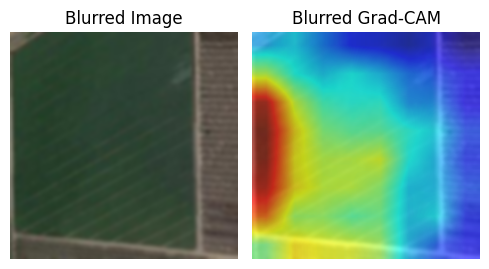

In [95]:
show_single_comparison(blurred, cam_blur, "Blurred", get_prediction(model, blurred))

The image is predicted as: (6, 'Grassland')


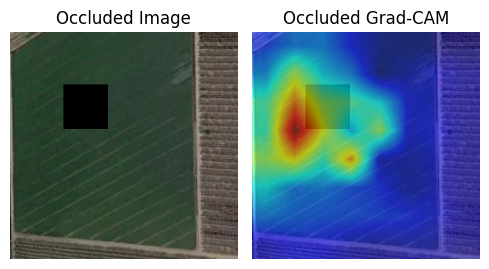

In [96]:
show_single_comparison(occluded, cam_occl, "Occluded", get_prediction(model, occluded))

The image is predicted as: (6, 'Grassland')


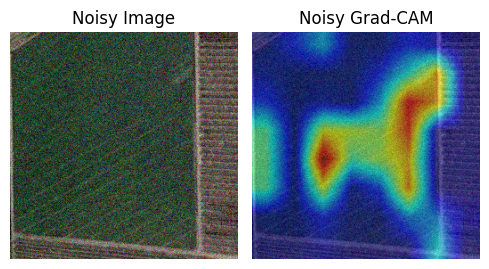

In [97]:
show_single_comparison(noisy, cam_noise, "Noisy", get_prediction(model, noisy))